In [2]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:

PROJECT_ROOT = os.path.abspath("..")

RAW_DATA_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "raw",
    "telco_customer_churn.csv"
)

PROCESSED_DATA_DIR = os.path.join(
    PROJECT_ROOT, "data", "processed"
)

FIGURES_DIR = os.path.join(
    PROJECT_ROOT, "reports", "figures"
)

os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", RAW_DATA_PATH)
print("Dataset exists:", os.path.exists(RAW_DATA_PATH))


Project root: c:\hari\project\customer-churn-intelligence
Dataset path: c:\hari\project\customer-churn-intelligence\data\raw\telco_customer_churn.csv
Dataset exists: True


In [4]:
df = pd.read_csv(RAW_DATA_PATH)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecur

In [6]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary[missing_summary["Missing Values"] > 0])


,Missing Values,Missing Percentage


In [7]:

# Check complete duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())


Duplicate rows: 0
Duplicate customer IDs: 0


In [8]:

print("Data type before conversion:")
print(df["TotalCharges"].dtype)

# Convert to numeric; invalid or blank values become NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("\nData type after conversion:")
print(df["TotalCharges"].dtype)

print("\nMissing TotalCharges values:", df["TotalCharges"].isnull().sum())


Data type before conversion:
str

Data type after conversion:
float64

Missing TotalCharges values: 11


In [9]:
missing_charges = df[df["TotalCharges"].isnull()]

display(
    missing_charges[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [10]:

# Check whether missing charges correspond to zero-tenure customers
print(
    "Missing charges with zero tenure:",
    ((df["TotalCharges"].isnull()) & (df["tenure"] == 0)).sum()
)

print(
    "Missing charges with non-zero tenure:",
    ((df["TotalCharges"].isnull()) & (df["tenure"] != 0)).sum()
)

# For zero-tenure customers, no accumulated charges is a reasonable assumption
zero_tenure_missing = (
    df["TotalCharges"].isnull() & (df["tenure"] == 0)
)

df.loc[zero_tenure_missing, "TotalCharges"] = 0

print("\nRemaining missing TotalCharges:", df["TotalCharges"].isnull().sum())


Missing charges with zero tenure: 11
Missing charges with non-zero tenure: 0

Remaining missing TotalCharges: 0


In [11]:

print("Dataset shape:", df.shape)

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))


Dataset shape: (7043, 21)

Missing values per column:


,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Data types:


,Data Type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [12]:

print("Churn value counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

print("\nOverall churn rate:")
churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"{churn_rate:.2f}%")


Churn value counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Overall churn rate:
26.54%


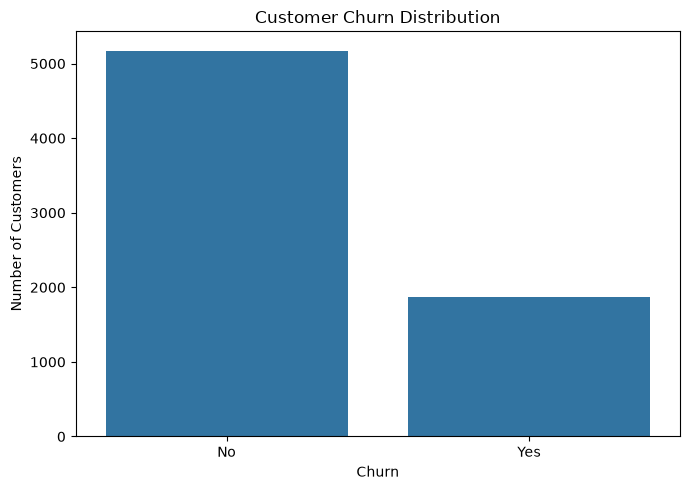

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [14]:

contract_analysis = (
    df.groupby("Contract", observed=True)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

contract_analysis["Churn_Rate"] = (
    contract_analysis["Churned_Customers"]
    / contract_analysis["Total_Customers"]
    * 100
)

contract_analysis = contract_analysis.sort_values(
    "Churn_Rate", ascending=False
)

display(contract_analysis.round(2))


,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


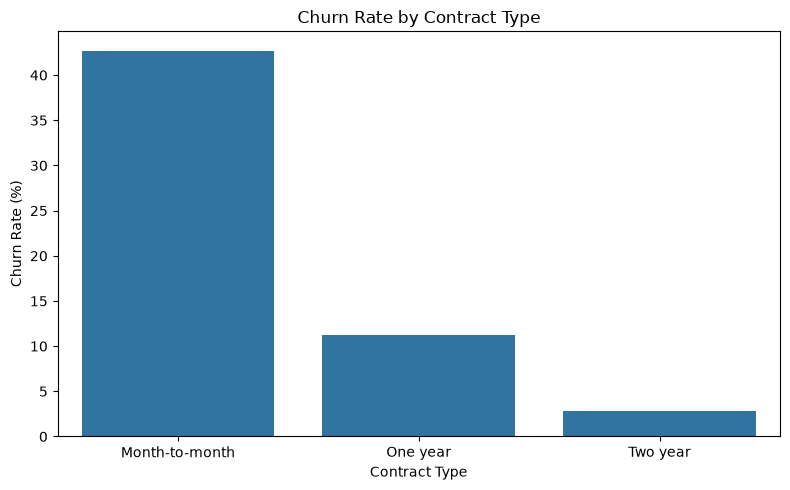

In [15]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_analysis.reset_index(),
    x="Contract",
    y="Churn_Rate"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "churn_by_contract.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [16]:

tenure_bins = [-1, 12, 24, 48, 72]
tenure_labels = [
    "0–12 months",
    "13–24 months",
    "25–48 months",
    "49–72 months"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure_analysis = (
    df.groupby("TenureGroup", observed=False)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

tenure_analysis["Churn_Rate"] = (
    tenure_analysis["Churned_Customers"]
    / tenure_analysis["Total_Customers"]
    * 100
)

display(tenure_analysis.round(2))


,Total_Customers,Churned_Customers,Churn_Rate
TenureGroup,,,
0–12 months,2186,1037,47.44
13–24 months,1024,294,28.71
25–48 months,1594,325,20.39
49–72 months,2239,213,9.51


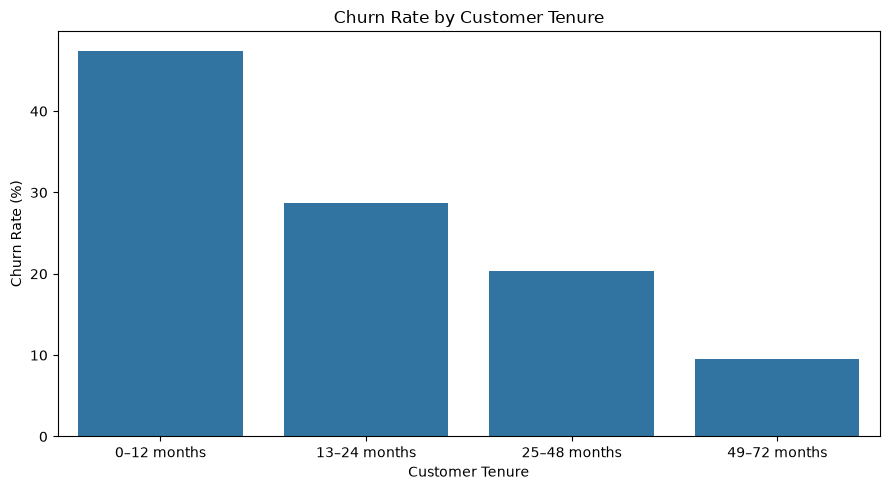

In [17]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_analysis.reset_index(),
    x="TenureGroup",
    y="Churn_Rate"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "churn_by_tenure.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [18]:

payment_analysis = (
    df.groupby("PaymentMethod", observed=True)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

payment_analysis["Churn_Rate"] = (
    payment_analysis["Churned_Customers"]
    / payment_analysis["Total_Customers"]
    * 100
)

payment_analysis = payment_analysis.sort_values(
    "Churn_Rate", ascending=False
)

display(payment_analysis.round(2))


,Total_Customers,Churned_Customers,Churn_Rate
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


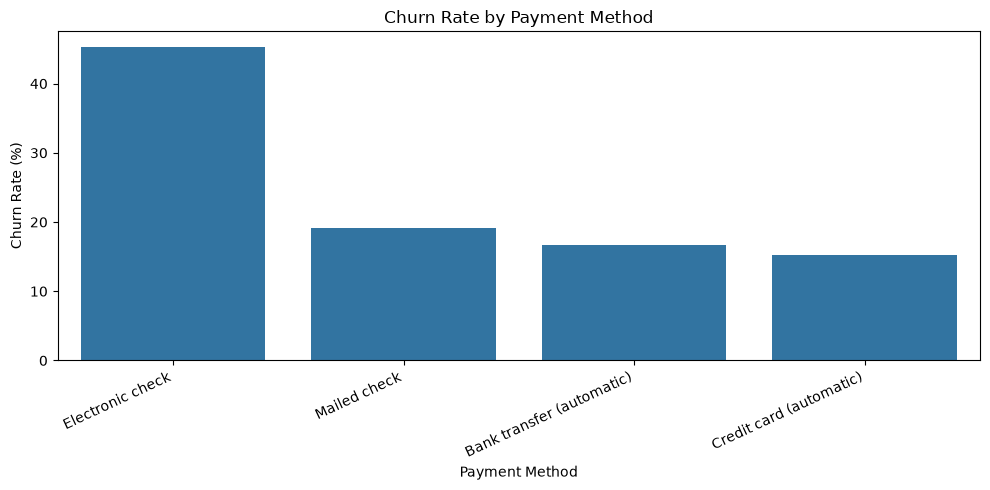

In [19]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis.reset_index(),
    x="PaymentMethod",
    y="Churn_Rate"
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "churn_by_payment_method.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


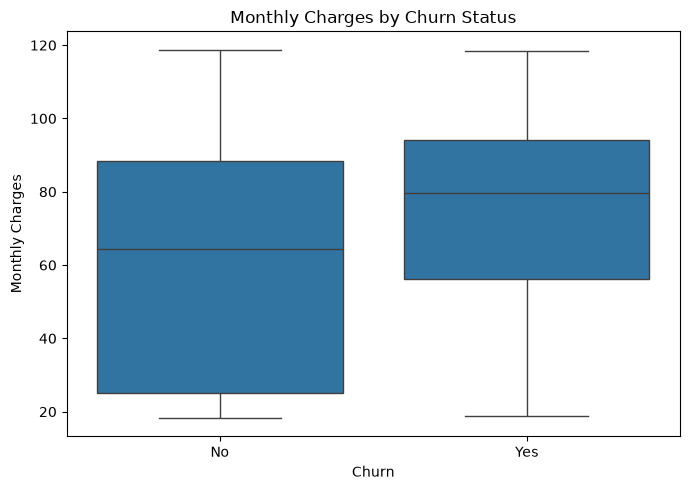

In [20]:

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "monthly_charges_by_churn.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [21]:

CLEANED_DATA_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "telco_customer_churn_clean.csv"
)

df.to_csv(CLEANED_DATA_PATH, index=False)

print("Cleaned dataset saved successfully.")
print("Saved to:", CLEANED_DATA_PATH)
print("Final dataset shape:", df.shape)


Cleaned dataset saved successfully.
Saved to: c:\hari\project\customer-churn-intelligence\data\processed\telco_customer_churn_clean.csv
Final dataset shape: (7043, 22)


In [22]:
import pandas as pd
import numpy as np

CLEANED_DATA_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "telco_customer_churn_clean.csv"
)

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0–12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25–48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0–12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25–48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0–12 months


In [23]:

print("Unique customer IDs:", df["customerID"].nunique())
print("Total records:", len(df))

df = df.drop(columns=["customerID"])

print("Customer ID removed.")
print("Updated shape:", df.shape)


Unique customer IDs: 7043
Total records: 7043
Customer ID removed.
Updated shape: (7043, 21)


In [24]:

X = df.drop(columns=["Churn", "TenureGroup"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [25]:

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal features:", len(numeric_features) + len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total features: 19


C:\Users\sreeh\AppData\Local\Temp\ipykernel_31208\3559757701.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [26]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Training records: 5634
Testing records: 1409

Training churn rate: 26.54 %
Testing churn rate: 26.54 %


In [27]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


In [28]:

from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Model pipeline created.")


Model pipeline created.


In [29]:

model.fit(X_train, y_train)

print("Model training completed successfully.")


Model training completed successfully.


In [30]:

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(np.round(y_proba[:10], 3))


First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted labels:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 1]

First 10 churn probabilities:
[0.118 0.852 0.146 0.66  0.06  0.805 0.697 0.292 0.009 0.652]


In [31]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully.")


Evaluation metrics imported successfully.


In [32]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

metrics["Score"] = metrics["Score"].round(4)

display(metrics)


,Metric,Score
0,Accuracy,0.7381
1,Precision,0.5043
2,Recall,0.7834
3,F1-Score,0.6136
4,ROC-AUC,0.8416


In [33]:

print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))


              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



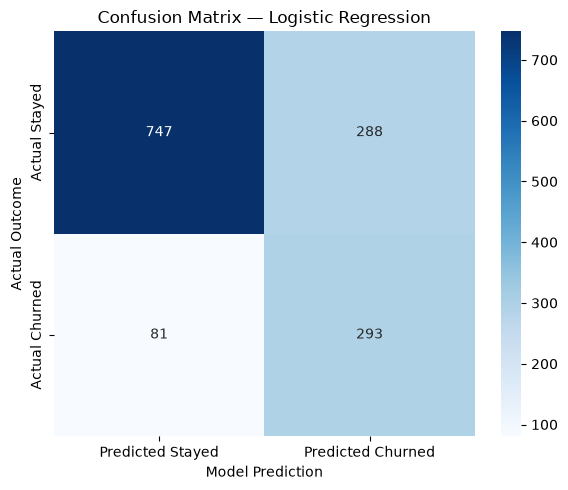

Confusion matrix values:
[[747 288]
 [ 81 293]]


In [34]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Stayed", "Predicted Churned"],
    yticklabels=["Actual Stayed", "Actual Churned"]
)

plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Model Prediction")
plt.ylabel("Actual Outcome")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "confusion_matrix_logistic_regression.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix values:")
print(cm)



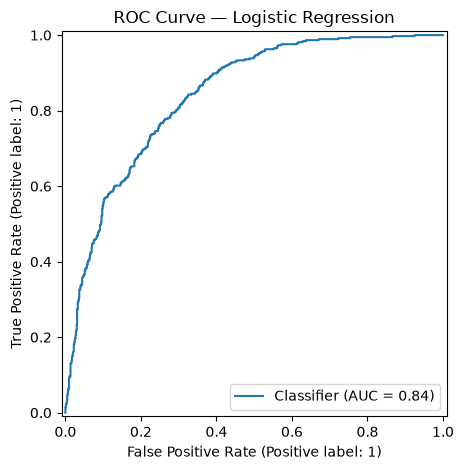

In [35]:

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_proba)

plt.title("ROC Curve — Logistic Regression")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "roc_curve_logistic_regression.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:

risk_results = X_test.copy()

risk_results["Actual_Churn"] = y_test
risk_results["Predicted_Churn"] = y_pred
risk_results["Churn_Probability"] = y_proba

risk_results["Risk_Level"] = pd.cut(
    risk_results["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"]
)

risk_results = risk_results.sort_values(
    "Churn_Probability",
    ascending=False
)

display(
    risk_results[
        [
            "tenure",
            "Contract",
            "MonthlyCharges",
            "Churn_Probability",
            "Risk_Level",
            "Actual_Churn"
        ]
    ].tail(15)
)


,tenure,Contract,MonthlyCharges,Churn_Probability,Risk_Level,Actual_Churn
4761,72,Two year,25.00,0.007616,Low,0
6423,72,Two year,24.25,0.007584,Low,0
984,72,Two year,23.75,0.007494,Low,0
1277,72,Two year,20.10,0.007453,Low,0
5828,72,Two year,24.45,0.007425,Low,0
1329,72,Two year,19.40,0.007063,Low,0
1815,72,Two year,20.50,0.006905,Low,0
3707,69,Two year,19.90,0.006402,Low,0
192,69,Two year,19.75,0.006250,Low,0
531,70,Two year,20.05,0.006098,Low,0


In [37]:

METRICS_PATH = os.path.join(
    PROJECT_ROOT,
    "reports",
    "logistic_regression_metrics.csv"
)

metrics.to_csv(METRICS_PATH, index=False)

RISK_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "customer_churn_risk_predictions.csv"
)

risk_results.to_csv(RISK_PATH, index=True)

print("Metrics saved to:", METRICS_PATH)
print("Risk predictions saved to:", RISK_PATH)


Metrics saved to: c:\hari\project\customer-churn-intelligence\reports\logistic_regression_metrics.csv
Risk predictions saved to: c:\hari\project\customer-churn-intelligence\data\processed\customer_churn_risk_predictions.csv


In [38]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")


Random Forest training completed.


In [39]:

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(rf_pred[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(np.round(rf_proba[:10], 3))


First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted labels:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 1]

First 10 churn probabilities:
[0.015 0.825 0.134 0.519 0.048 0.772 0.576 0.193 0.017 0.611]


In [40]:

rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1-Score": f1_score(y_test, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_proba)
}

rf_metrics_df = pd.DataFrame([rf_metrics])

display(rf_metrics_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7587,0.531,0.7781,0.6312,0.8399


In [41]:

logistic_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
}

comparison_df = pd.DataFrame([
    logistic_metrics,
    rf_metrics
])

display(
    comparison_df.set_index("Model").round(4)
)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
Random Forest,0.7587,0.5310,0.7781,0.6312,0.8399


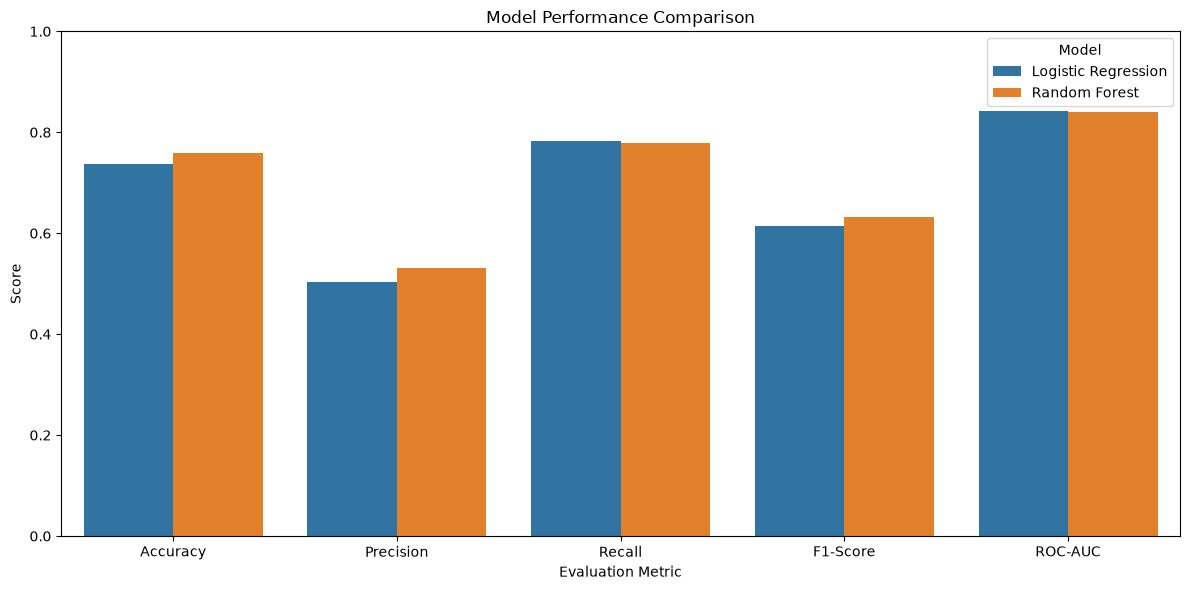

In [42]:

comparison_plot = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


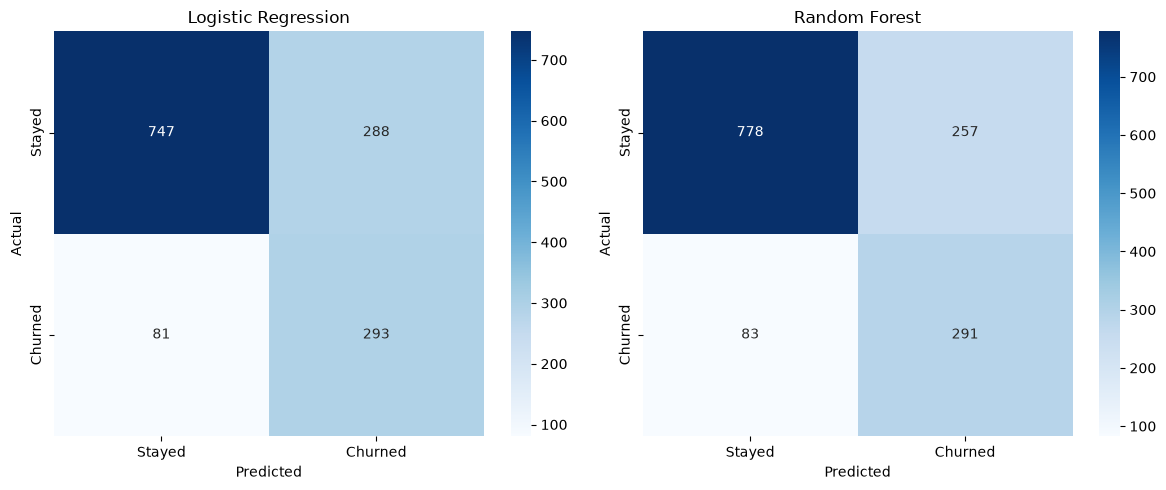

In [43]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models_to_plot = [
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred)
]

for ax, (model_name, predictions) in zip(axes, models_to_plot):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed", "Churned"],
        yticklabels=["Stayed", "Churned"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "model_confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [44]:

fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_classifier = rf_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance_df.head(15).round(4))


,Feature,Importance
36,categorical__Contract_Month-to-month,0.1288
1,numeric__tenure,0.1244
3,numeric__TotalCharges,0.1014
2,numeric__MonthlyCharges,0.0707
38,categorical__Contract_Two year,0.0645
18,categorical__OnlineSecurity_No,0.0601
16,categorical__InternetService_Fiber optic,0.0503
27,categorical__TechSupport_No,0.0481
43,categorical__PaymentMethod_Electronic check,0.0362
37,categorical__Contract_One year,0.0205


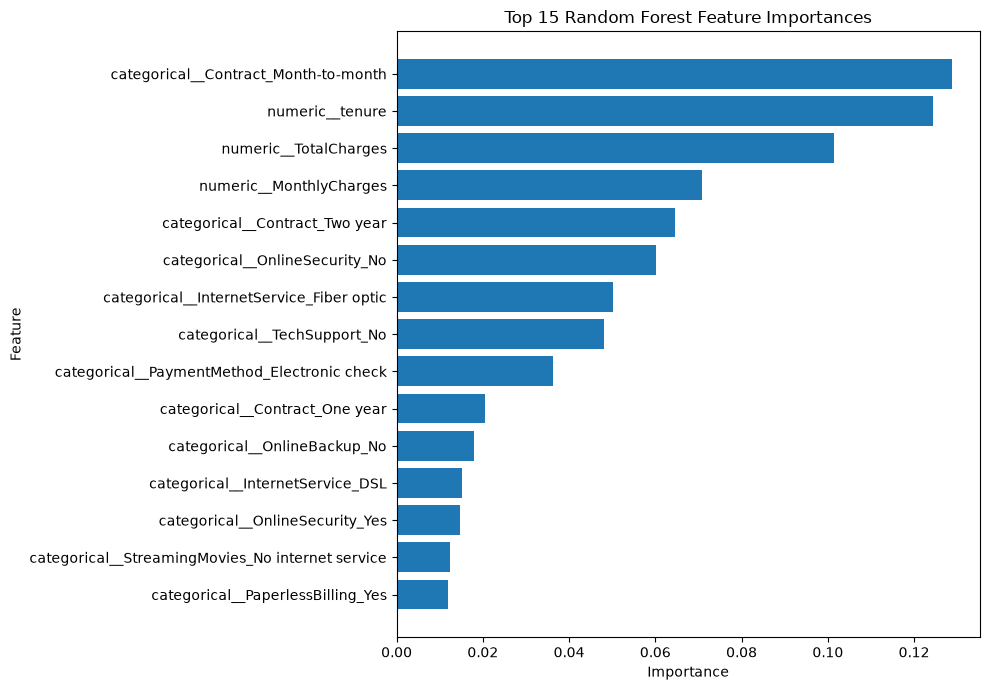

In [45]:

top_features = feature_importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "random_forest_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [46]:

COMPARISON_PATH = os.path.join(
    PROJECT_ROOT,
    "reports",
    "model_comparison.csv"
)

FEATURE_IMPORTANCE_PATH = os.path.join(
    PROJECT_ROOT,
    "reports",
    "random_forest_feature_importance.csv"
)

comparison_df.to_csv(COMPARISON_PATH, index=False)
feature_importance_df.to_csv(FEATURE_IMPORTANCE_PATH, index=False)

print("Saved model comparison:", COMPARISON_PATH)
print("Saved feature importances:", FEATURE_IMPORTANCE_PATH)


Saved model comparison: c:\hari\project\customer-churn-intelligence\reports\model_comparison.csv
Saved feature importances: c:\hari\project\customer-churn-intelligence\reports\random_forest_feature_importance.csv
